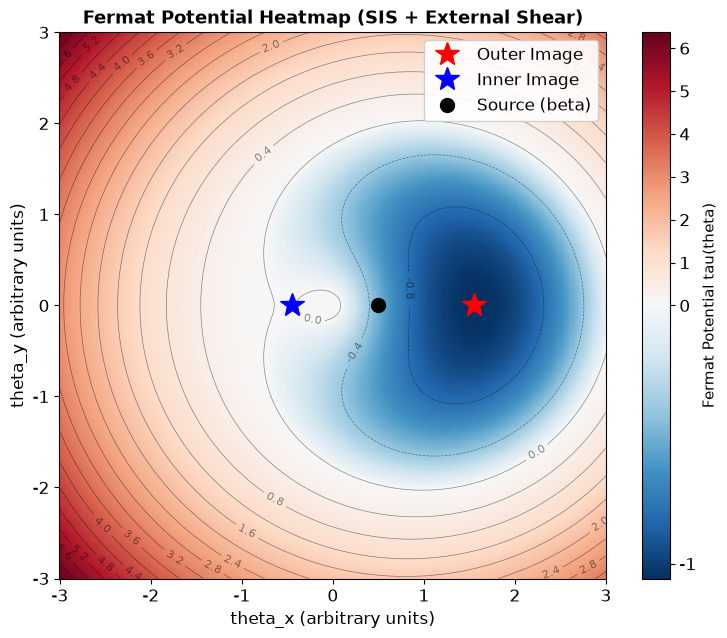

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Circle
from matplotlib.colors import TwoSlopeNorm
import os

plt.rcParams['font.size'] = 12
plt.rcParams['axes.unicode_minus'] = False
plt.rcParams['figure.dpi'] = 100

os.makedirs('figures', exist_ok=True)
# 图2：SIS + 外部剪切的费马势热力图
theta_E = 1.0
beta = np.array([0.5, 0.0])
gamma_ext = 0.05

x = np.linspace(-3, 3, 500)
y = np.linspace(-3, 3, 500)
X, Y = np.meshgrid(x, y)
R = np.sqrt(X**2 + Y**2)
R = np.maximum(R, 0.02)

tau = ((X - beta[0])**2 + (Y - beta[1])**2) / 2 - theta_E * R

psi_ext = 0.5 * gamma_ext * (X**2 - Y**2)
tau = tau - psi_ext

fig, ax = plt.subplots(figsize=(8, 6.5))

norm = TwoSlopeNorm(vmin=tau.min(), vcenter=0.0, vmax=tau.max())
im = ax.pcolormesh(X, Y, tau, cmap='RdBu_r', shading='auto', norm=norm)

cs = ax.contour(X, Y, tau, levels=20, colors='k',
                linewidths=0.5, alpha=0.45)
ax.clabel(cs, inline=True, fontsize=8, fmt='%.1f')

beta_norm = np.linalg.norm(beta)
theta_outer = beta + theta_E * beta / beta_norm + np.array([gamma_ext, 0])
theta_inner = beta - theta_E * beta / beta_norm + np.array([gamma_ext, 0])

ax.plot(theta_outer[0], theta_outer[1], 'r*', ms=18,
        label='Outer Image', zorder=5)
ax.plot(theta_inner[0], theta_inner[1], 'b*', ms=18,
        label='Inner Image', zorder=5)
ax.plot(beta[0], beta[1], 'ko', ms=10,
        label='Source (beta)', zorder=5)

cbar = plt.colorbar(im, ax=ax)
cbar.set_label('Fermat Potential tau(theta)', fontsize=11)

ax.set_xlabel('theta_x (arbitrary units)')
ax.set_ylabel('theta_y (arbitrary units)')
ax.set_title('Fermat Potential Heatmap (SIS + External Shear)',
             fontsize=13, fontweight='bold')
ax.legend(loc='upper right', framealpha=0.9)
ax.set_aspect('equal')

plt.tight_layout()
plt.savefig('figures/fig2_fermat_potential.png', dpi=300, bbox_inches='tight')
plt.show()